##### Feladat

Határozzuk meg az igénybevételi függvényeket és rajzoljuk fel az igénybevételi ábrákat!

<img src="img/01.jpg" alt="Feladat" width=420px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
L = 1 # m

p = 4 # kN/m

# Rúdirányú koordináta
x = sp.symbols('x')

##### Előjelkonvenció

Az igénybevételek előjelét az alábbi előjelkonvenció szerint határozzuk meg (lásd a 8.1 feladatot):

<img src="img/02.jpg" alt="Feladat" width=300px>

##### Szabadtest ábra

<img src="img/03.jpg" alt="Feladat" width=420px>

A megoszló terhelést az egyensúlyi egyenletekben az eredőjével ($F_p = p L$) helyettesítjük, amely a terhelt szakasz felénél, az $A$ ponttól $L/2$ távolságra hat.

##### A reakciók

In [3]:
A_x, A_y, B_y = sp.symbols('A_x, A_y, B_y')

##### Egyensúlyi egyenletek

In [4]:
# x irányú erő egyensúly
eq1 = A_x
display(Math(rf'\sum F_x = 0 \quad \longrightarrow \quad {latex(eq1)} = 0 \qquad (1)'))

# y irányú erő egyensúly
eq2 = A_y - p*L + B_y
display(Math(rf'\sum F_y = 0 \quad \longrightarrow \quad {latex(eq2)} = 0 \qquad (2)'))

# z irányú nyomatéki egyensúly az A pontra
eq3 = -p*L*L*sp.Rational(1, 2) + B_y*L
display(Math(rf'\sum M_A = 0 \quad \longrightarrow \quad {latex(eq3)} = 0 \qquad (3)'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Egyensúlyi egyenletek megoldása

In [5]:
sol = sp.solve([eq1, eq2, eq3], [A_x, A_y, B_y])

A_xsol = sol[A_x]
display(Math(rf'A_x = {latex(A_xsol)} ~ \mathrm{{kN}}'))

A_ysol = sol[A_y]
display(Math(rf'A_y = {latex(A_ysol)} ~ \mathrm{{kN}}'))

B_ysol = sol[B_y]
display(Math(rf'B_y = {latex(B_ysol)} ~ \mathrm{{kN}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Szakaszok

* A megoszló terhelés a teljes tartón hat, a tartó belsejében nincs koncentrált erő vagy nyomaték → elég 1 szakasz!

* $x \in [0, L]$

##### Az igénybevételi függvények

* Balról redukálunk, mivel a reakciók már ismertek.

* A $K$ keresztmetszettől balra az $A_x$ és $A_y$ reakcióerők és a megoszló terhelés hatnak. A megoszló terhelést az eredőjével ($F_p$) helyettesítjük, amely a terhelt szakasz felénél, a $K$ keresztmetszettől $x/2$ távolságra hat.

In [6]:
# A balról elhagyott részen ható megoszló terhelés eredője (F_p-vel helyettesítjük)
F_p = p*x
display(Math(rf'F_p = p \cdot x = {latex(F_p)} ~ \mathrm{{kN}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Normálerő: az A_x erő jobbra mutat, ami balról nézve negatív
N = -A_xsol
display(Math(rf'N(x) = {latex(N)}'))

# Nyíróerő: az A_y erő felfelé mutat (balról nézve pozitív), az F_p erő lefelé mutat (balról nézve negatív)
V = A_ysol - F_p
display(Math(rf'V(x) = A_y - p \cdot x = {latex(V)} ~ \mathrm{{kN}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Hajlítónyomaték: az A_y nyomatéka a K pontra az óramutató járásával megegyező (balról nézve negatív),
# az F_p nyomatéka (erőkar: x/2) az óramutató járásával ellentétes (balról nézve pozitív)
M_h = sp.expand(-A_ysol*x + F_p*x/2)
display(Math(rf'M_h(x) = -A_y \cdot x + p \frac{{x^2}}{{2}} = {latex(M_h)} ~ \mathrm{{kNm}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Csavarónyomaték: nincs rúdirányú nyomaték
M_t = sp.Integer(0)
display(Math(rf'M_t(x) = {latex(M_t)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Ellenőrzés

* A $B$ támasznál ($x = L$) a hajlítónyomaték nulla, a nyíróerő pedig jobbról nézve a $B_y$ reakcióerő: $V(x=L) = -B_y$.

* Derivált kapcsolatok: $V'(x) = p(x)$ és $M_h'(x) = -V(x)$.

A megoszló terhelés lefelé ($-y$ irányba) mutat, így $p(x) = -p$.

In [7]:
# Az igénybevételek a B támasznál
display(Math(rf'M_h(x=L) = {latex(M_h.subs(x, L))} ~ \mathrm{{kNm}}'))
display(Math(rf'V(x=L) = {latex(V.subs(x, L))} ~ \mathrm{{kN}} \qquad -B_y = {latex(-B_ysol)} ~ \mathrm{{kN}}'))

# A megoszló terhelés függvénye
p_x = -p
display(Math(rf'p(x) = {latex(p_x)} ~ \mathrm{{kN/m}}'))

# A nyíróerő deriváltja
dV = sp.diff(V, x)
display(Math(rf"V'(x) = {latex(dV)} \qquad p(x) = {latex(p_x)}"))

# A hajlítónyomaték deriváltja
dM_h = sp.diff(M_h, x)
display(Math(rf"M_h'(x) = {latex(dM_h)} \qquad -V(x) = {latex(-V)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Látható, hogy az összefüggések teljesülnek.

##### Ábrázolás

* $V(x)$: lineáris egyenes, 2 pontot kiszámolunk, behúzzuk.

* $M_h(x)$: parabola. Ahol $V(x) = 0$, ott $M_h(x)$-nek szélsőértéke van (vízszintes érintő).

In [8]:
# A nyíróerő a tartó két végén
display(Math(rf'V(x=0) = {latex(V.subs(x, 0))} ~ \mathrm{{kN}} \qquad V(x=L) = {latex(V.subs(x, L))} ~ \mathrm{{kN}}'))

# A szélsőérték helye: V(x) = 0
x_sz = sp.solve(V, x)[0]
display(Math(rf'V(x) = 0 \quad \longrightarrow \quad x = {latex(round(x_sz, 2))} ~ \mathrm{{m}}'))

M_hsz = M_h.subs(x, x_sz)
display(Math(rf'M_h(x={latex(round(x_sz, 2))}) = {latex(round(M_hsz, 2))} ~ \mathrm{{kNm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [9]:
def igenybeveteli_abra(ax, f, x_0, x_1, felirat, szin='red'):
    # A függvény kiértékelése numerikusan az [x_0, x_1] tartományon
    x_vals = np.linspace(x_0, x_1, 201)
    f_vals = sp.lambdify(x, f, 'numpy')(x_vals) * np.ones_like(x_vals) # Konstans függvény esetén is tömböt kapunk
    # A függvény görbéje (zorder: az x tengely fölé rajzoljuk)
    ax.plot(x_vals, f_vals, color=szin, lw=1.5, zorder=3)
    # Satírozás a görbe és az x tengely között (mint a kézi rajzokon)
    ax.vlines(x_vals[::10], 0, f_vals[::10], color=szin, lw=0.8)
    # Lezárás a tartomány két végén
    ax.vlines([x_0, x_1], 0, [f_vals[0], f_vals[-1]], color=szin, lw=1.5, zorder=3)
    # Az x tengely
    ax.axhline(0, color='black', lw=1)
    ax.set_ylabel(felirat)
    ax.grid(True, alpha=0.5)

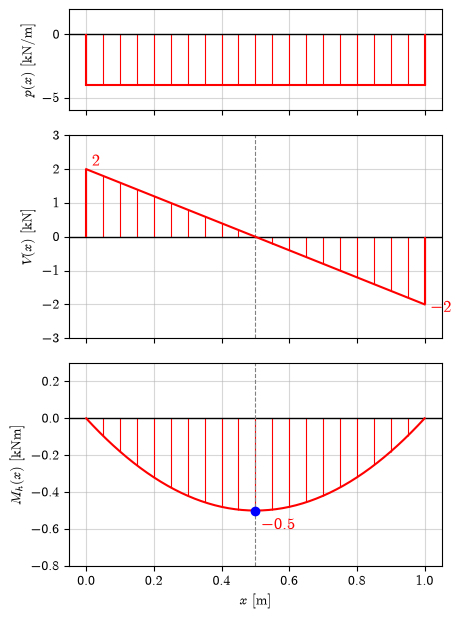

In [10]:
fig, axs = plt.subplots(3, 1, figsize=(12/2.54, 16/2.54), sharex=True, gridspec_kw={'height_ratios': [1, 2, 2]})

# p(x)
igenybeveteli_abra(axs[0], p_x, 0, L, r'$p(x) ~ [\mathrm{kN/m}]$')
axs[0].set_ylim(-6, 2)

# V(x)
igenybeveteli_abra(axs[1], V, 0, L, r'$V(x) ~ [\mathrm{kN}]$')
axs[1].annotate(rf'${latex(V.subs(x, 0))}$', xy=(0, float(V.subs(x, 0))), xytext=(4, 2), textcoords='offset points', color='red', fontsize=12)
axs[1].annotate(rf'${latex(V.subs(x, L))}$', xy=(L, float(V.subs(x, L))), xytext=(4, -6), textcoords='offset points', color='red', fontsize=12)
axs[1].set_ylim(-3, 3)

# M_h(x) és a szélsőértéke
igenybeveteli_abra(axs[2], M_h, 0, L, r'$M_h(x) ~ [\mathrm{kNm}]$')
axs[2].plot(float(x_sz), float(M_hsz), 'o', color='blue', zorder=10)
axs[2].annotate(rf'${latex(round(M_hsz, 2))}$', xy=(float(x_sz), float(M_hsz)), xytext=(4, -14), textcoords='offset points', color='red', fontsize=12)
axs[2].set_ylim(-0.8, 0.3)

# Segédvonal: a szélsőérték helye (V(x) = 0)
for ax in axs[1:]:
    ax.axvline(float(x_sz), color='gray', ls='--', lw=0.8)

axs[2].set_xlabel(r'$x ~ [\mathrm{m}]$')
plt.tight_layout()
plt.savefig('igenybeveteli_fuggvenyek.pdf') # Az ábra mentése PDF dokumentumba
plt.show()

A nyíróerő lineáris, a hajlítónyomaték másodfokú (parabola) függvény. A terhelés szimmetrikus, így a hajlítónyomaték szélsőértéke a tartó felénél van.